# 02 · Perfil de volumen

**Objetivo:** localizar **dónde** (a qué precios) se concentró el volumen
negociado: las zonas que el mercado aceptó y las que rechazó. Es la primera
aproximación a "dónde están las ballenas" y el mapa de niveles sobre el que se
apoyará el análisis Wyckoff.

**Contenido**
1. Conceptos y método
2. Perfil de los últimos 180 días (4h)
3. Compras vs. ventas por nivel (delta)
4. Perfil histórico: por qué medir en USD y no en BTC
5. ¿El precio vuelve al POC? Test con grupo de control
6. Conclusiones

## 1. Conceptos y método

| Término | Significado |
|---|---|
| **Perfil de volumen** | Histograma horizontal: volumen negociado en cada nivel de precio |
| **POC** (Point of Control) | Nivel con más volumen: el precio "más aceptado" |
| **Área de valor** (VAL–VAH) | Rango alrededor del POC que concentra el 70 % del volumen |
| **HVN** (High Volume Node) | Pico del perfil: zona de acumulación de posiciones |
| **LVN** (Low Volume Node) | Valle del perfil: zona que el precio cruzó rápido, con poco interés |

**Método:** una vela solo dice cuánto volumen hubo entre su `low` y su `high`,
no a qué precio exacto. Se asume que el volumen se reparte **uniformemente**
dentro del recorrido de la vela. Con velas de 4h y periodos de meses el error es
pequeño; en la Fase 4 se usarán operaciones individuales (`aggTrades`) para
tener el precio exacto.

El área de valor se construye con el método clásico de Market Profile: desde el
POC se añade cada vez el nivel vecino con más volumen hasta llegar al 70 %.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
import seaborn as sns
from scipy.stats import binomtest

from btc_radar.datos import cargar_velas
from btc_radar.graficos import grafico_perfil_volumen
from btc_radar.volume_profile import area_de_valor, nodos_volumen, perfil_volumen

pio.renderers.default = "plotly_mimetype+png"
sns.set_theme(style="whitegrid")

d = cargar_velas("1d")
h = cargar_velas("4h")

## 2. Perfil de los últimos 180 días (4h)

In [2]:
ventana = h.iloc[-180 * 6 :]  # 6 velas de 4h por día
perfil = perfil_volumen(ventana, n_niveles=100)
niveles = area_de_valor(perfil)
nodos = nodos_volumen(perfil)

ancho = perfil["precio_alto"].iloc[0] - perfil["precio_bajo"].iloc[0]
print(f"Periodo: {ventana.index[0]:%Y-%m-%d} → {ventana.index[-1]:%Y-%m-%d}")
print(f"Niveles de {ancho:,.0f} USDT")
print(f"POC {niveles.poc:,.0f} | VAH {niveles.vah:,.0f} | VAL {niveles.val:,.0f}")
print(f"Último cierre: {ventana['close'].iloc[-1]:,.0f}")
nodos.round(0)

Periodo: 2026-05-26 → 2026-11-22
Niveles de 323 USDT
POC 64,003 | VAH 78,361 | VAL 57,389
Último cierre: 60,737


,precio,volumen,tipo
0,64003.0,139487.0,HVN
1,70456.0,4143.0,LVN
2,77555.0,53989.0,HVN
3,82394.0,23093.0,LVN
4,83685.0,42627.0,HVN


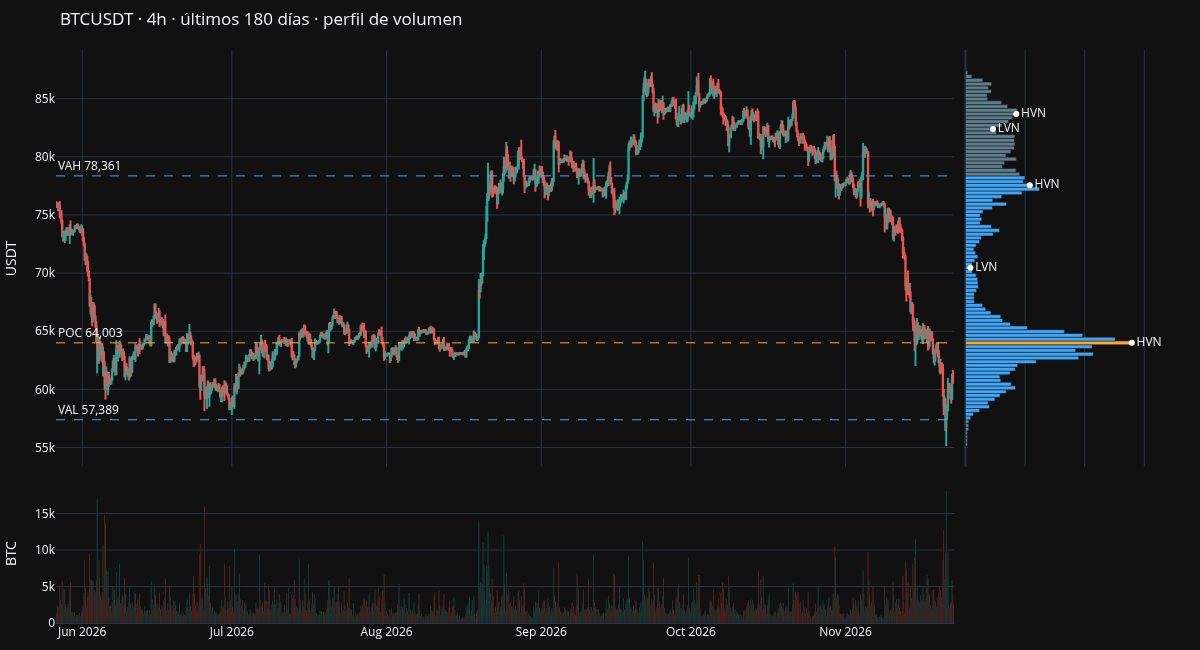

In [3]:
titulo = "BTCUSDT · 4h · últimos 180 días · perfil de volumen"
grafico_perfil_volumen(ventana, perfil, niveles, nodos, titulo).show(
    width=1200, height=650
)

**Lectura (a fecha del análisis, nov-2026):**
- El **POC (~64.000)** coincide con el rango lateral de junio a agosto: ahí se
  negoció la mayor parte del volumen del periodo. Es la zona de "valor justo"
  que aceptaron compradores y vendedores.
- El perfil tiene **dos zonas** de volumen (60-66k y 75-86k) separadas por un
  **LVN cerca de 70.000**. Es el tramo que el precio cruzó de un salto en la
  subida de agosto y en la caída de noviembre: casi nadie negoció ahí.
- El precio ha vuelto por debajo del POC y está cerca del VAL (~57.400), el
  borde inferior del área de valor.

**Conexión con Wyckoff:** un rango lateral con un POC marcado es exactamente el
tipo de estructura que Wyckoff analiza (¿acumulación o distribución?). Los LVN
son zonas donde el precio tiende a moverse rápido porque no hay posiciones que
lo frenen.

## 3. Compras vs. ventas por nivel (delta)

El **delta** de cada nivel es `volumen comprador agresivo − volumen vendedor
agresivo`. Positivo: dominaron quienes compraron a mercado; negativo, quienes
vendieron a mercado.

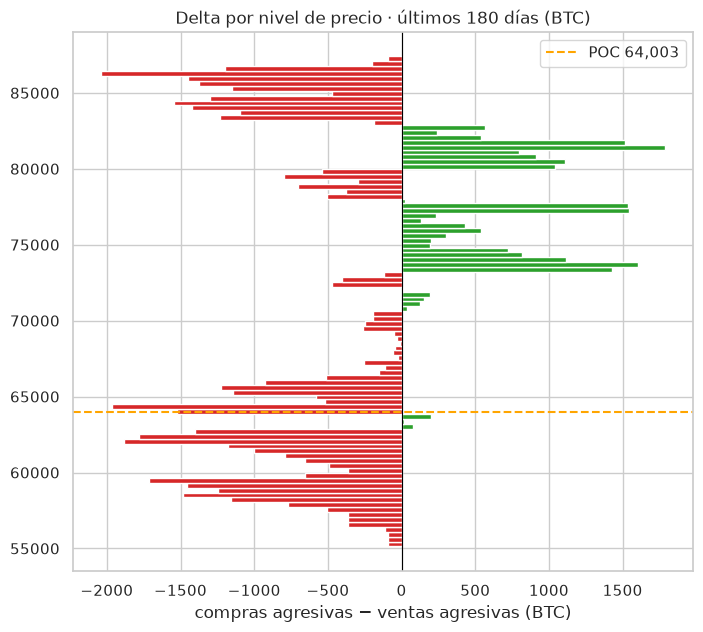

Delta total: -28,883 BTC (-0.95% del volumen)


precio
(0, 60000]       -10455.0
(60000, 66000]   -17155.0
(66000, 72000]    -1641.0
(72000, 79000]     8263.0
(79000, 90000]    -7894.0
Name: delta (BTC), dtype: float64

In [4]:
perfil["delta"] = perfil["volumen_compra"] - perfil["volumen_venta"]

fig, ax = plt.subplots(figsize=(8, 7))
colores = np.where(perfil["delta"] >= 0, "tab:green", "tab:red")
ax.barh(perfil["precio"], perfil["delta"], height=ancho, color=colores)
ax.axhline(niveles.poc, color="orange", ls="--", label=f"POC {niveles.poc:,.0f}")
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Delta por nivel de precio · últimos 180 días (BTC)")
ax.set_xlabel("compras agresivas − ventas agresivas (BTC)")
ax.legend()
plt.show()

tramos = pd.cut(perfil["precio"], [0, 60_000, 66_000, 72_000, 79_000, 90_000])
delta_total = perfil["delta"].sum()
print(
    f"Delta total: {delta_total:,.0f} BTC "
    f"({delta_total / perfil['volumen'].sum():.2%} del volumen)"
)
perfil.groupby(tramos, observed=True)["delta"].sum().round(0).rename("delta (BTC)")

**Lectura:**
- En el conjunto del periodo compras y ventas agresivas casi se compensan
  (delta ≈ −1 % del volumen).
- Por tramos sí hay diferencias: en la **zona del POC (60-66k)** dominó la
  **venta agresiva**, mientras que entre **72k y 79k** dominó la **compra
  agresiva**.

**Precaución:** "agresivo" no significa "ballena". Vender a mercado puede ser
una ballena saliendo o miles de pequeños inversores con miedo. Para separar el
tamaño de cada operación hacen falta los trades individuales → Fase 4.

## 4. Perfil histórico: por qué medir en USD y no en BTC

Con todo el historial (2017-2026) aparece un sesgo: cuando BTC valía 5.000 USD,
con el mismo dinero se negociaban 20 veces más unidades que cuando valía
100.000. Medido en **BTC**, los años baratos pesan artificialmente más. Medido
en **USD** (`quote_volume`), cada nivel pesa por el dinero que realmente se
movió.

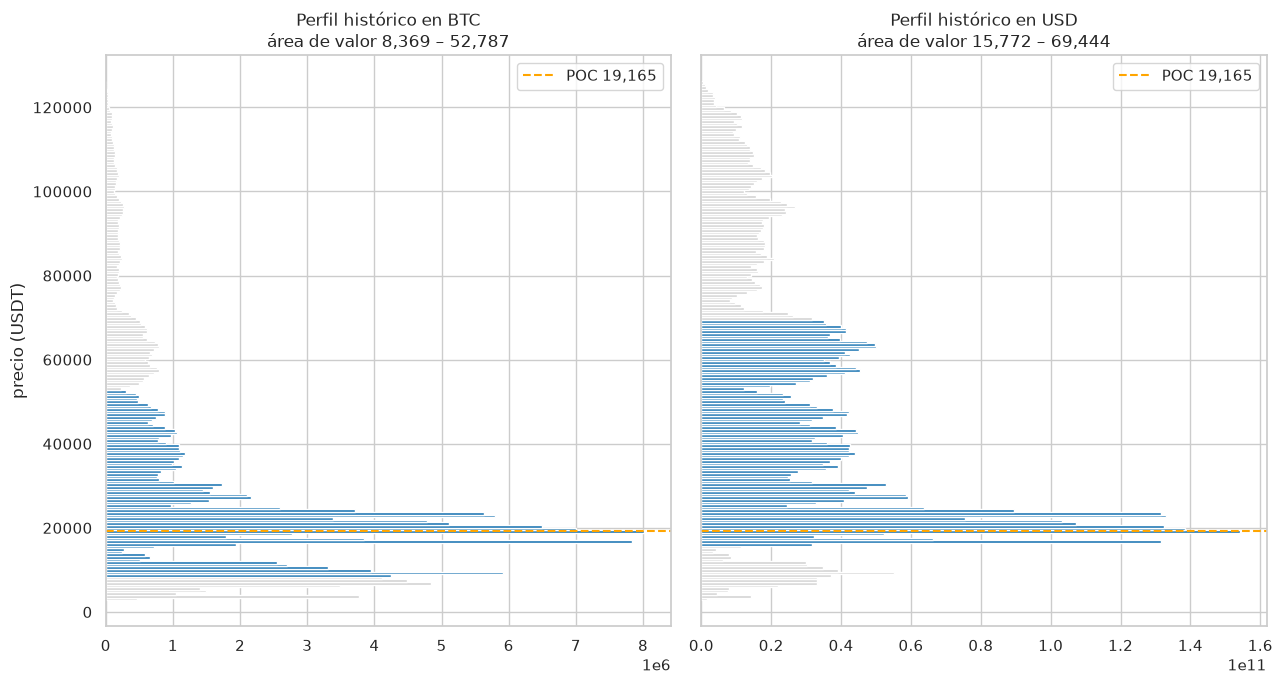

,0,2,4,6,8,10,12,14
precio,9295.0,17314.0,19782.0,23484.0,27802.0,42608.0,63583.0,96279.0


In [5]:
p_btc = perfil_volumen(d, n_niveles=200)
p_usd = perfil_volumen(d, n_niveles=200, en_usd=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for ax, p, unidad in [(axes[0], p_btc, "BTC"), (axes[1], p_usd, "USD")]:
    n = area_de_valor(p)
    en_area = p["precio"].between(n.val, n.vah)
    ax.barh(
        p["precio"],
        p["volumen"],
        height=p["precio_alto"] - p["precio_bajo"],
        color=np.where(en_area, "tab:blue", "lightgray"),
    )
    ax.axhline(n.poc, color="orange", ls="--", label=f"POC {n.poc:,.0f}")
    ax.set_title(
        f"Perfil histórico en {unidad}\nárea de valor {n.val:,.0f} – {n.vah:,.0f}"
    )
    ax.legend(loc="upper right")
axes[0].set_ylabel("precio (USDT)")
plt.tight_layout()
plt.show()

nodos_volumen(p_usd).query("tipo == 'HVN'")[["precio"]].round(0).T

**Lectura:**
- En ambas medidas el **POC histórico está cerca de 19.000**: el rango del
  mercado bajista de 2022-2023, la zona donde más tiempo y volumen se acumuló.
- Pero en **BTC** el área de valor llega solo hasta ~53.000 y los niveles
  recientes casi desaparecen. En **USD** el área de valor se extiende hasta
  ~69.000 y aparecen nodos de alto volumen en **~63.600 y ~96.300**, con un
  vacío (LVN) cerca de **74.000**.

**Decisión:** para periodos largos el perfil se calcula **en USD**. En ventanas
cortas (semanas o meses) la diferencia es despreciable y se puede usar BTC.

## 5. ¿El precio vuelve al POC? Test con grupo de control

Una idea muy repetida en trading es que el POC "atrae" al precio. Se pone a
prueba:

1. Para cada semana (o mes) se calcula el POC con sus velas de 4h.
2. Se comprueba si el precio **toca ese POC en el periodo siguiente**.
3. **Grupo de control:** el POC suele estar cerca del precio actual, así que
   "tocarlo" es fácil por pura cercanía. Para separar ese efecto se compara con
   un **nivel espejo**: a la misma distancia del cierre que el POC, pero del
   lado contrario. Si el POC atrae de verdad, debería tocarse más que el espejo.
4. Se usa una prueba de McNemar exacta (binomial sobre los casos en que solo
   uno de los dos niveles se toca).

In [6]:
def test_retorno_al_poc(velas: pd.DataFrame, frecuencia: str) -> dict:
    periodos = velas.index.tz_localize(None).to_period(frecuencia)
    grupos = [g for _, g in velas.groupby(periodos)]
    resultados = []
    for actual, siguiente in zip(grupos[:-1], grupos[1:], strict=True):
        poc = area_de_valor(perfil_volumen(actual, n_niveles=50)).poc
        espejo = 2 * actual["close"].iloc[-1] - poc
        bajo, alto = siguiente["low"].min(), siguiente["high"].max()
        resultados.append((bajo <= poc <= alto, bajo <= espejo <= alto))

    r = pd.DataFrame(resultados, columns=["poc", "espejo"])
    solo_poc = int((r["poc"] & ~r["espejo"]).sum())
    solo_espejo = int((~r["poc"] & r["espejo"]).sum())
    return {
        "periodos": len(r),
        "toca POC": f"{r['poc'].mean():.1%}",
        "toca espejo": f"{r['espejo'].mean():.1%}",
        "solo POC": solo_poc,
        "solo espejo": solo_espejo,
        "p-valor": round(binomtest(solo_poc, solo_poc + solo_espejo).pvalue, 3),
    }


pd.DataFrame(
    {"semanal": test_retorno_al_poc(h, "W"), "mensual": test_retorno_al_poc(h, "M")}
)

,semanal,mensual
periodos,483,111
toca POC,72.7%,68.5%
toca espejo,72.7%,71.2%
solo POC,92,22
solo espejo,92,25
p-valor,1.0,0.771


**Lectura:** el precio toca el POC del periodo anterior en ~70 % de los
casos, lo que a primera vista parece confirmar la idea del "imán". Pero el
**nivel espejo**, a la misma distancia y sin ningún significado, se toca **con
la misma frecuencia**. La diferencia no es estadísticamente significativa
(p-valor alto).

**Conclusión:** el POC no atrae al precio más que cualquier otro nivel a la
misma distancia; parece un imán solo porque suele estar cerca del precio.

**Lo que este test no descarta:** que el POC funcione como **soporte o
resistencia** (que el precio reaccione al tocarlo). Eso se medirá en el
backtest de la Fase 6, junto a las señales Wyckoff.

## 6. Conclusiones

1. **Mapa de niveles:** en los últimos 180 días el volumen se concentra en el
   rango 60-66k (POC ~64.000) y en 75-86k, con un vacío de volumen (LVN) cerca
   de 70.000.
2. **Delta por nivel:** dominó la venta agresiva en la zona del POC y la compra
   agresiva entre 72 y 79k. No identifica ballenas por sí solo.
3. **Unidad de medida:** en periodos largos el perfil debe medirse en USD; en
   BTC se sobrerrepresentan los años de precio bajo.
4. **Mito del imán:** el POC no se revisita más que un nivel de control a la
   misma distancia. Los niveles de volumen se usarán como contexto, y su valor
   como soporte o resistencia se medirá en el backtest.

**Siguiente paso → Fase 4:** operaciones individuales (`aggTrades`) para
detectar operaciones grandes (ballenas), su lado comprador o vendedor y el CVD.